In [140]:
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import numpy as np
import sys
import subprocess
import matplotlib.pyplot as plt
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
from pathlib import Path
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration")

import momentum_fluxes.momentum_flux_funcs as tx

orog_data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

sonde_ids = []

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/" 

raw_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_raw_sonde_data").glob("*.nc"))
coarse_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_coarse_sonde_data").glob("*.nc"))
model_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_model_sonde_data").glob("*.nc"))

index = 3

# Paths for the sonde and model data

sonde_id = raw_sonde_list[index].stem[13:21]

raw_data_path = raw_sonde_list[index]
coarse_data_path = coarse_sonde_list[index]
model_data_path = model_sonde_list[index]

data_path_orog = "orography_u-eb392_run1_0p3km.nc"

original_model_data_path_4 = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

# Import in some data to see what it looks like
plot_title_affix = f"{sonde_id}"
cubelist_s_path = f"{coarse_data_path}"
cubelist_m_path = f"{model_data_path}"
cubelist_r_path = f"{raw_data_path}"

cubelist_mo_path = f"{original_model_data_path}"
orog_cube_path = f"{data_path_base}/{data_path_orog}"

cubelist_s = iris.load(cubelist_s_path)
cubelist_m = iris.load(cubelist_m_path)
cubelist_mo = iris.load(cubelist_mo_path)
orog_cube = iris.load(orog_cube_path)


In [141]:
# First, extract the relevant cubes 
u_s_wind_nonans, u_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "eastward_wind")
v_s_wind_nonans, v_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "northward_wind")
T_s_nonans, T_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_temperature")
Theta_s_nonans, Theta_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_potential_temperature")
pressure_s_nonans, pressure_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_pressure")

u_m_wind_nonans, u_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "eastward_wind")
v_m_wind_nonans, v_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "northward_wind")
T_m_nonans, T_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_temperature")
Theta_m_nonans, Theta_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_potential_temperature")
pressure_m_nonans, pressure_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_pressure")

u_r_wind_nonans, u_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "eastward_wind")
v_r_wind_nonans, v_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "northward_wind")
T_r_nonans, T_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_temperature")
Theta_r_nonans, Theta_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_potential_temperature")
pressure_r_nonans, pressure_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_pressure")
alt_nonans, alt_mask = tx.nonans_cubedata(cubelist_r_path, "altitude")
time_nonans, time_mask = tx.nonans_cubedata(cubelist_r_path, "Elapsed Time")


# Extract the vert_levels to plot as background
cross_heights = tx.vert_levels_for_sonde(sonde_data_path=cubelist_s_path, 
                                  model_sonde_data_path=cubelist_m_path, 
                                  model_data_path=cubelist_mo_path, 
                                  model_orog_path=orog_cube_path)
                                  
# Now, fit a polynomial to the u and T data and find coeffs
p_deg = 4
u_s_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_s_wind_nonans, p_deg)
v_s_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_s_wind_nonans, p_deg)
T_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_s_nonans, p_deg)
pressure_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_s_nonans, p_deg)
Theta_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_s_nonans, p_deg+1)

u_m_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_m_wind_nonans, p_deg)
v_m_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_m_wind_nonans, p_deg)
T_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_m_nonans, p_deg)
pressure_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_m_nonans, p_deg)
Theta_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_m_nonans, p_deg+1)

u_r_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_r_wind_nonans, p_deg)
v_r_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_r_wind_nonans, p_deg)
T_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_r_nonans, p_deg)
pressure_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_r_nonans, p_deg)
Theta_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_r_nonans, p_deg+1)

# Find the mean profiles using the calculated coefficients
u_s_wind_mean = u_s_wind_coeffs(alt_nonans)
v_s_wind_mean = v_s_wind_coeffs(alt_nonans)
T_s_mean = T_s_coeffs(alt_nonans)
pressure_s_mean = pressure_s_coeffs(alt_nonans)
Theta_s_mean = Theta_s_coeffs(alt_nonans)

u_m_wind_mean = u_m_wind_coeffs(alt_nonans)
v_m_wind_mean = v_m_wind_coeffs(alt_nonans)
T_m_mean = T_m_coeffs(alt_nonans)
pressure_m_mean = pressure_m_coeffs(alt_nonans)
Theta_m_mean = Theta_m_coeffs(alt_nonans)

u_r_wind_mean = u_r_wind_coeffs(alt_nonans)
v_r_wind_mean = v_r_wind_coeffs(alt_nonans)
T_r_mean = T_r_coeffs(alt_nonans)
pressure_r_mean = pressure_r_coeffs(alt_nonans)
Theta_r_mean = Theta_r_coeffs(alt_nonans)

# Find the perturbations using raw - mean
u_s_wind_prime = u_s_wind_nonans - u_s_wind_mean
v_s_wind_prime = v_s_wind_nonans - v_s_wind_mean
T_s_prime = T_s_nonans - T_s_mean
pressure_s_prime = pressure_s_nonans - pressure_s_mean
Theta_s_prime = Theta_s_nonans - Theta_s_mean

u_m_wind_prime = u_m_wind_nonans - u_m_wind_mean
v_m_wind_prime = v_m_wind_nonans - v_m_wind_mean
T_m_prime = T_m_nonans - T_m_mean
pressure_m_prime = pressure_m_nonans - pressure_m_mean
Theta_m_prime = Theta_m_nonans - Theta_m_mean

u_r_wind_prime = u_r_wind_nonans - u_r_wind_mean
v_r_wind_prime = v_r_wind_nonans - v_r_wind_mean
T_r_prime = T_r_nonans - T_r_mean
pressure_r_prime = pressure_r_nonans - pressure_r_mean
Theta_r_prime = Theta_r_nonans - Theta_r_mean

# Normalise the Temperatures to find T prime hat
T_hat_s_prime = T_s_prime / T_s_mean
T_hat_m_prime = T_m_prime / T_m_mean
T_hat_r_prime = T_r_prime / T_r_mean

In [142]:
# Mean horizontal wind
U_s= np.sqrt(u_s_wind_mean**2 + v_s_wind_mean**2)
d2U_dz2_s_coeffs_0 = 1/(U_s) * ((u_s_wind_coeffs.deriv(1))**2 + (v_s_wind_coeffs.deriv(1))**2 + u_s_wind_coeffs*(u_s_wind_coeffs.deriv(2)) + v_s_wind_coeffs*(v_s_wind_coeffs.deriv(2)))
d2U_dz2_s_coeffs_1 = -1/(U_s**3) * ((u_s_wind_coeffs*(u_s_wind_coeffs.deriv(1)) + v_s_wind_coeffs*(v_s_wind_coeffs.deriv(1)))**2)
d2U_dz2_s_coeffs = d2U_dz2_s_coeffs_0 + d2U_dz2_s_coeffs_1

U_m= np.sqrt(u_m_wind_mean**2 + v_m_wind_mean**2)
d2U_dz2_m_coeffs_0 = 1/(U_m) * ((u_m_wind_coeffs.deriv(1))**2 + (v_m_wind_coeffs.deriv(1))**2 + u_m_wind_coeffs*(u_m_wind_coeffs.deriv(2)) + v_m_wind_coeffs*(v_m_wind_coeffs.deriv(2)))
d2U_dz2_m_coeffs_1 = -1/(U_m**3) * ((u_m_wind_coeffs*(u_m_wind_coeffs.deriv(1)) + v_m_wind_coeffs*(v_m_wind_coeffs.deriv(1)))**2)
d2U_dz2_m_coeffs = d2U_dz2_m_coeffs_0 + d2U_dz2_m_coeffs_1

U_r= np.sqrt(u_r_wind_mean**2 + v_r_wind_mean**2)
d2U_dz2_r_coeffs_0 = 1/(U_r) * ((u_r_wind_coeffs.deriv(1))**2 + (v_r_wind_coeffs.deriv(1))**2 + u_r_wind_coeffs*(u_r_wind_coeffs.deriv(2)) + v_r_wind_coeffs*(v_r_wind_coeffs.deriv(2)))
d2U_dz2_r_coeffs_1 = -1/(U_r**3) * ((u_r_wind_coeffs*(u_r_wind_coeffs.deriv(1)) + v_r_wind_coeffs*(v_r_wind_coeffs.deriv(1)))**2)
d2U_dz2_r_coeffs = d2U_dz2_r_coeffs_0 + d2U_dz2_r_coeffs_1

In [143]:
# Calculate the scorer parameter
# https://resources.eumetrain.org/data/4/452/navmenu.php?tab=4&page=5.0.0

# l**2 = N**2 / U**2 - (dU**2/dz**2)/U

N_s = tx.brunt_vaisala_from_sonde(cubelist_s_path)
N_r = tx.brunt_vaisala_from_sonde(cubelist_r_path)
N_m = tx.brunt_vaisala_from_sonde(cubelist_m_path)

# Mean horizontal wind
l_s_sqrd = N_s**2 / U_s**2 - (d2U_dz2_s_coeffs(alt_nonans))/U_s
l_m_sqrd = N_m**2 / U_m**2 - (d2U_dz2_m_coeffs(alt_nonans))/U_m
l_r_sqrd = N_r**2 / U_r**2 - (d2U_dz2_r_coeffs(alt_nonans))/U_r



Brunt Vaisala Frequency Calculated
Brunt Vaisala Frequency Calculated
Brunt Vaisala Frequency Calculated


In [144]:
# Investigate the distributions
perc = 99.999

perc_s = np.percentile(l_s_sqrd, perc)
l_s_sqrd_valid = l_s_sqrd.copy()
l_s_sqrd_valid[l_s_sqrd > perc_s] = np.nan

perc_m = np.percentile(l_m_sqrd, perc)
l_m_sqrd_valid = l_m_sqrd.copy()
l_m_sqrd_valid[l_m_sqrd > perc_m] = np.nan

perc_r = np.percentile(l_r_sqrd, perc)
l_r_sqrd_valid = l_r_sqrd.copy()
l_r_sqrd_valid[l_r_sqrd > perc_r] = np.nan


/home/users/jmtd42/miniforge3/envs/teamx/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


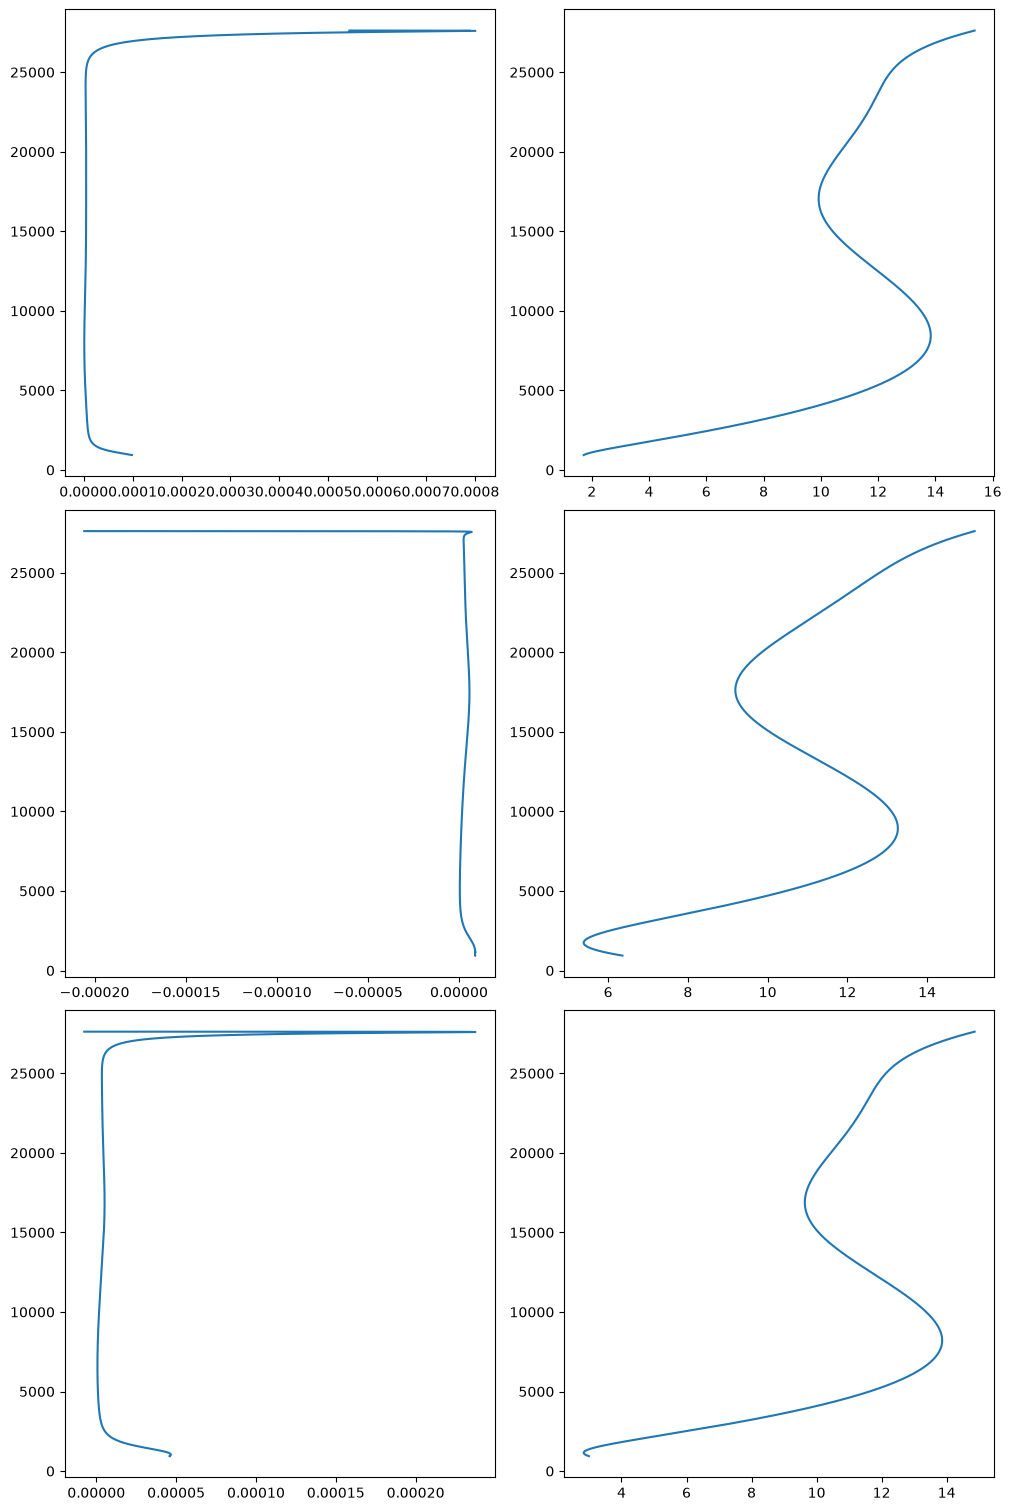

In [146]:
# Plot profiles
fig = plt.figure(figsize=(10,15), layout="constrained")
ax = fig.subplots(3,2)

bin_n = 5
ax[0][0].plot(l_s_sqrd_valid, alt_nonans)
ax[0][1].plot(U_s, alt_nonans)

ax[1][0].plot(l_m_sqrd_valid, alt_nonans)
ax[1][1].plot(U_m, alt_nonans)

ax[2][0].plot(l_r_sqrd_valid, alt_nonans)
ax[2][1].plot(U_r, alt_nonans)



